# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 3 - Module 3
### **Practical 9: Differential Evolution (DE)**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module III: Genetic Algorithms and Evolutionary Computing |
| **Student Name** | *Aakash Sarang* |
| **Enrollment No.** | *2023BTCSE001* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To implement a simple Differential Evolution (DE) algorithm for solving an optimization problem using Python.

### 2. Theory: Differential Evolution (DE/rand/1/bin)

Differential Evolution is a population-based continuous optimizer:
1. **Mutation:** For target vector $\mathbf{x}_i$, pick 3 distinct vectors $\mathbf{x}_{r1}, \mathbf{x}_{r2}, \mathbf{x}_{r3}$ and form mutant $\mathbf{v}_i = \mathbf{x}_{r1} + F (\mathbf{x}_{r2} - \mathbf{x}_{r3})$.
2. **Crossover:** Mix $\mathbf{x}_i$ and $\mathbf{v}_i$ with crossover rate $CR$ to form trial vector $\mathbf{u}_i$.
3. **Selection:** Replace $\mathbf{x}_i$ with $\mathbf{u}_i$ if $f(\mathbf{u}_i) \le f(\mathbf{x}_i)$.

### 3. Step 1: Implementing DE on the Rastrigin Function

Best Solution: [-3.e-06  3.e-06]
Best Fitness:  0.00000000


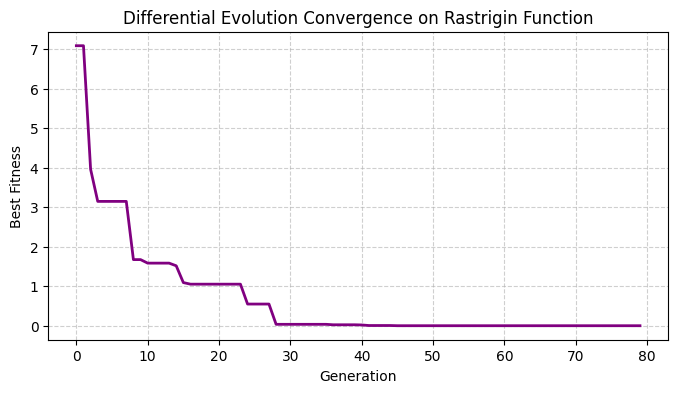

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

def rastrigin(x):
    return 10 * len(x) + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))

pop_size, dim, gens = 30, 2, 80
F, CR = 0.8, 0.7
low, high = -5.12, 5.12

pop = np.random.uniform(low, high, (pop_size, dim))
fitness = np.array([rastrigin(ind) for ind in pop])
history = []

for _ in range(gens):
    for i in range(pop_size):
        idxs = [idx for idx in range(pop_size) if idx != i]
        r1, r2, r3 = pop[np.random.choice(idxs, 3, replace=False)]
        mutant = np.clip(r1 + F * (r2 - r3), low, high)

        j_rand = np.random.randint(dim)
        cross_mask = (np.random.rand(dim) < CR) | (np.arange(dim) == j_rand)
        trial = np.where(cross_mask, mutant, pop[i])

        f_trial = rastrigin(trial)
        if f_trial <= fitness[i]:
            pop[i] = trial
            fitness[i] = f_trial

    history.append(np.min(fitness))

best_idx = np.argmin(fitness)
print(f"Best Solution: {np.round(pop[best_idx], 6)}")
print(f"Best Fitness:  {fitness[best_idx]:.8f}")

plt.figure(figsize=(8, 4))
plt.plot(history, color='purple', linewidth=2)
plt.title("Differential Evolution Convergence on Rastrigin Function")
plt.xlabel("Generation")
plt.ylabel("Best Fitness")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 4. Conclusion
We implemented DE/rand/1/bin and successfully minimized the multimodal Rastrigin function.